In [76]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [77]:
n=1
p=0.3
sample_size=20

samples = np.random.binomial(n=1,p=p,size=sample_size)

print(samples)

[0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0]


In [78]:
clicks = np.sum(samples == 1)
no_clicks = np.sum(samples == 0)

print(clicks)
print(no_clicks)

1
19


In [79]:
t_mean =n * p
t_var = n * p * (1-p)

e_mean = np.mean(samples)
e_var = np.var(samples)

print("t_mean: ",t_mean)
print("e_mean: ",e_mean)
print("t_var: ",t_var)
print("e_var: ",e_var)

t_mean:  0.3
e_mean:  0.05
t_var:  0.21
e_var:  0.04749999999999999


In [80]:
t_pmf = [1-p,p]
e_pmf  = [no_clicks/sample_size,clicks/sample_size]

print(t_pmf)
print(e_pmf)

[0.7, 0.3]
[0.95, 0.05]


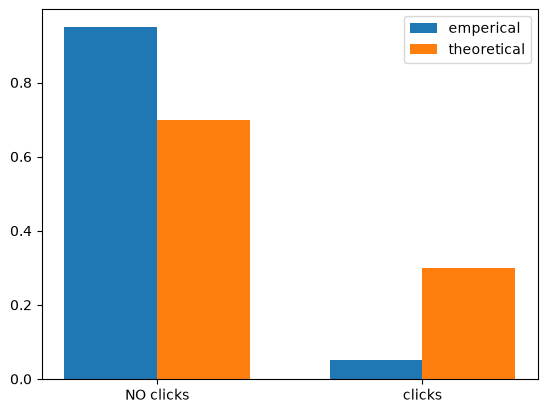

In [81]:
x=[0,1]
width = 0.35
plt.bar(np.array(x)-width/2,e_pmf,width,label="emperical")
plt.bar(np.array(x)+width/2,t_pmf,width,label="theoretical")
plt.xticks(x,["NO clicks","clicks"])
plt.legend()
plt.show()

Problem Set 2: ML Use Case: Number of Fraudulent Transactions Flagged
Problem statement: A fraud-detection model examines 50 transactions every 
hour. Assume that each transaction has a 4% probability of being flagged as 
potentially fraudulent.


Let:
Initially assume that individual flagging decisions are independent.
The fraud investigation team can examine at most four flagged transactions per 
hour.
Find:


1: Simulate the operation of the fraud-detection system for 20,000 independent one-hour periods.
During every simulated hour:


 exactly 50 transactions are examined; 


 each transaction has a flagging probability of 0.04 


 records the total number of flagged transactions.


Hint: use np.random.binomial function



In [82]:
n=50
p=0.4
sample_size=20000

sample = np.random.binomial(n=n,p=p,size=sample_size)

print(sample[:20])

print(len(sample))

[20 23 25 20 21 16 17 18 18 19 21 28 20 20 19 22 24 23 24 15]
20000


In [83]:
import pandas as pd

emp_mean = np.mean(sample)
t_mean = n * p

emp_var = np.var(samples)
t_var= n * p * (1-p)

data = {
    "metrics":["mean","variance"],
    "emperical" :[emp_mean,emp_var],
    "theoretical":[t_mean,t_var]
}

data = pd.DataFrame(data)
data

,metrics,emperical,theoretical
0,mean,20.0145,20.0
1,variance,0.0475,12.0


In [84]:
prob_exed_emp = np.mean(sample>4)
print(prob_exed_emp)

0.99995


In [85]:
from scipy.stats import binom

prob_exed_t = 1-binom.cdf(4,n,p)

print("Empirical P(X > 4):", prob_exed_emp)
print("Theoretical P(X > 4):", prob_exed_t)

Empirical P(X > 4): 0.99995
Theoretical P(X > 4): 0.999999580683531


A monitoring system checks 12 independent server requests during each minute. Each request has a 0.20 probability of failing. Let X be the number of failed requests in one minute.

Write Python code to:

·        Identify the distribution of X, its parameters, and its possible values.

·        Simulate 20,000 minutes and calculate the empirical PMF for every possible value of X.

·        Calculate the theoretical PMF and plot it alongside the empirical PMF.

·        Calculate the empirical and theoretical expectation and variance. Present the four values in a table.

·    Estimate (P>=4) from the simulation and calculate it theoretically.

In [86]:
n=12
p=0.2
sample_size = 20000

samples = np.random.binomial(n=n,p=p,size = sample_size)

print(samples[:20])

[1 3 3 4 2 3 1 5 5 3 4 4 1 3 3 1 3 2 3 5]


In [87]:
x = np.arange(n+1)
print(x)

[ 0  1  2  3  4  5  6  7  8  9 10 11 12]


In [88]:
emp_pmf = np.bincount(samples,minlength=len(x))/sample_size
theo_pmf = binom.pmf(x,n,p)

print(emp_pmf)
print(theo_pmf)

[6.9400e-02 2.0705e-01 2.8695e-01 2.3230e-01 1.3395e-01 5.0750e-02
 1.5350e-02 3.7500e-03 4.0000e-04 1.0000e-04 0.0000e+00 0.0000e+00
 0.0000e+00]
[6.87194767e-02 2.06158430e-01 2.83467842e-01 2.36223201e-01
 1.32875551e-01 5.31502203e-02 1.55021476e-02 3.32188877e-03
 5.19045120e-04 5.76716800e-05 4.32537600e-06 1.96608000e-07
 4.09600000e-09]


In [89]:
metrics = {
    "emp":[np.mean(samples),np.var(samples),emp_pmf],
    "theo":[n*p,n*p*(1-p),theo_pmf]
}
metrics = pd.DataFrame(metrics)
metrics

,emp,theo
0,2.38985,2.4
1,1.916167,1.92
2,"[0.0694, 0.20705, 0.28695, 0.2323, 0.13395, 0....","[0.06871947673599998, 0.20615843020800007, 0.2..."


plot teo vs emp

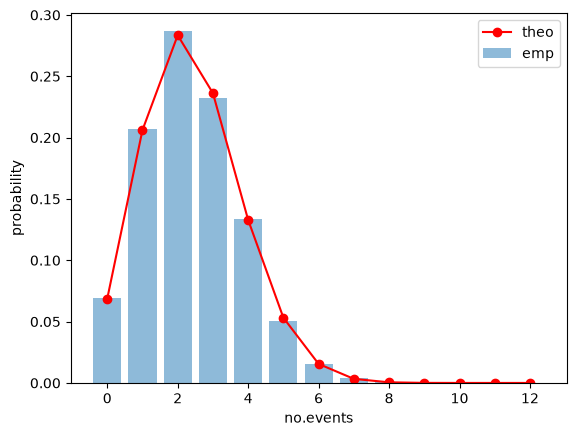

In [90]:
plt.bar(x,emp_pmf,alpha=0.5,label="emp")
plt.plot(x,theo_pmf,'ro-',label="theo")

plt.xlabel("no.events")
plt.ylabel("probability")

plt.legend()
plt.show()

In [91]:
prob_exed_t = binom.cdf(3,n,p)
print("theoretically: (P>=4)",prob_exed_t)
print("emperically: (P>=4)",np.mean(samples>=4))


theoretically: (P>=4) 0.7945689497599997
emperically: (P>=4) 0.2043


1.     A monitoring system checks 12 independent server requests during each minute. Each request has a 0.20 probability of failing. Let X be the number of failed requests in one minute.

Write Python code to:

·        Identify the distribution of X, its parameters, and its possible values.

·        Simulate 20,000 minutes and calculate the empirical PMF for every possible value of X.

·        Calculate the theoretical PMF and plot it alongside the empirical PMF.

·        Calculate the empirical and theoretical expectation and variance. Present the four values in a table.


In [92]:
n=12
p=0.4
sample_size = 20000

samples = np.random.binomial(n=n,p=p,size = sample_size)
print(samples[:20])
x=np.arange(n+1)
print(x)

[4 4 5 3 4 4 3 4 5 3 3 4 4 7 4 6 4 4 5 2]
[ 0  1  2  3  4  5  6  7  8  9 10 11 12]


In [93]:
import pandas as pd

emp_mean = np.mean(samples)
t_mean = n * p

emp_var = np.var(samples)
t_var= n * p * (1-p)

data = {
    "metrics":["mean","variance"],
    "emperical" :[emp_mean,emp_var],
    "theoretical":[t_mean,t_var]
}

data = pd.DataFrame(data)
data

,metrics,emperical,theoretical
0,mean,4.810800,4.80
1,variance,2.842203,2.88


In [94]:
e_pmf = np.bincount(samples,minlength=len(x))/sample_size
print(e_pmf)

t_pmf = binom.pmf(x,n,p)
print(t_pmf)

[1.8000e-03 1.7200e-02 6.1800e-02 1.4015e-01 2.1325e-01 2.3130e-01
 1.7690e-01 1.0040e-01 4.1950e-02 1.2550e-02 2.4500e-03 2.0000e-04
 5.0000e-05]
[2.17678234e-03 1.74142587e-02 6.38522819e-02 1.41893960e-01
 2.12840940e-01 2.27030335e-01 1.76579150e-01 1.00902371e-01
 4.20426547e-02 1.24570829e-02 2.49141658e-03 3.01989888e-04
 1.67772160e-05]


plot theo vs emp

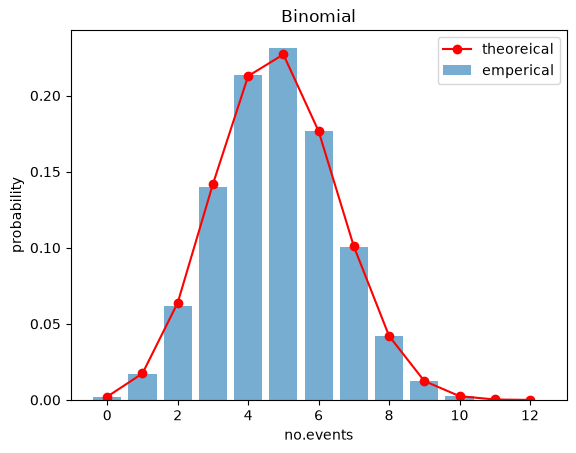

In [95]:
plt.bar(x,e_pmf,alpha = 0.6,label = "emperical")
plt.plot(x,t_pmf,'ro-',label = "theoreical")
plt.title("Binomial")
plt.xlabel("no.events")
plt.ylabel("probability")
plt.legend()
plt.show()

Binomial

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom

np.random.seed(42)

n=12
p=0.2
sample_size = 20000

samples = np.random.binomial(n=n,p=p,size=sample_size)
print(samples[:20])
x=np.arange(n+1)
print(x)

[2 5 3 3 1 1 0 4 3 3 0 5 4 1 1 1 2 2 2 2]
[ 0  1  2  3  4  5  6  7  8  9 10 11 12]


In [8]:
e_pmf = np.bincount(samples,minlength=len(x))/sample_size
t_pmf = binom.pmf(x,n,p)

print(e_pmf)
print(t_pmf)

[0.06925 0.20615 0.286   0.2335  0.13125 0.0545  0.0151  0.0038  0.00045
 0.      0.      0.      0.     ]
[6.87194767e-02 2.06158430e-01 2.83467842e-01 2.36223201e-01
 1.32875551e-01 5.31502203e-02 1.55021476e-02 3.32188877e-03
 5.19045120e-04 5.76716800e-05 4.32537600e-06 1.96608000e-07
 4.09600000e-09]


In [9]:
theo = {
    "t_mean" : n * p,
    "t_var" : n * p * (1-p)
}
emperical = {
    "e_mean" : np.mean(samples),
    "e_var" : np.var(samples)
}

data = {
    "metrics" : ["theoretical","emperical"],
    "mean" : [theo["t_mean"],emperical["e_mean"]],
    "var" : [theo["t_var"],emperical["e_var"]]
}

data = pd.DataFrame(data)
data

,metrics,mean,var
0,theoretical,2.40000,1.920000
1,emperical,2.39695,1.927381


plot

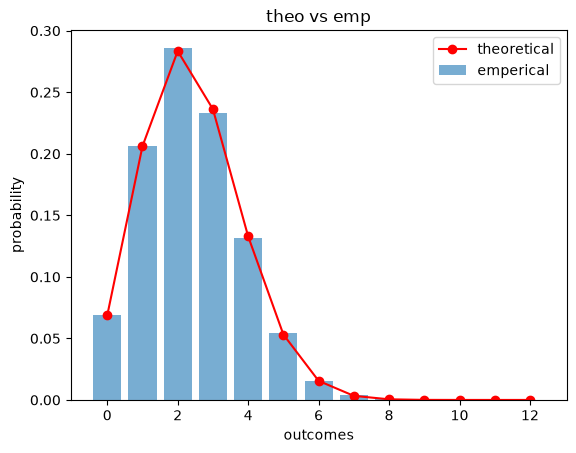

In [10]:
plt.bar(x,e_pmf,alpha=0.6,label="emperical")
plt.plot(x,t_pmf,'ro-',label="theoretical")

plt.title("theo vs emp")
plt.xlabel("outcomes")
plt.ylabel("probability")

plt.legend()
plt.show()

In [11]:
t_pmf_less = binom.cdf(3,n,p)
e_pmf_less = np.mean(samples<=4)

print("Theoretical(p<=4): ",t_pmf_less)
print("emperical(p<=4): ",e_pmf_less)


Theoretical(p<=4):  0.7945689497599997
emperical(p<=4):  0.92615


Bernoillis

In [16]:
n=1
p=0.3
sample_size=20

samples = np.random.binomial(n=1,p=p,size=sample_size)
print(samples)

x=[0,1]
print(x)

[0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 1 0 0 1 0]
[0, 1]


In [17]:
clicks = np.sum(samples == 1)
noclicks = np.sum(samples == 0)

e_pmf = {
    0:noclicks/sample_size,
    1:clicks/sample_size
}

t_pmf = {
    0:1-p,
    1:p
}

print(e_pmf)
print(t_pmf)

{0: 0.8, 1: 0.2}
{0: 0.7, 1: 0.3}


In [19]:
t_mean = p
t_var = p * (1-p)

e_mean = np.mean(samples)
e_var = np.var(samples)

data = {
    "metrics" : ["emperical","theoretical"],
    "mean" : [e_mean,t_mean],
    "var": [e_var,t_var]
}

data = pd.DataFrame(data)
data

,metrics,mean,var
0,emperical,0.2,0.16
1,theoretical,0.3,0.21


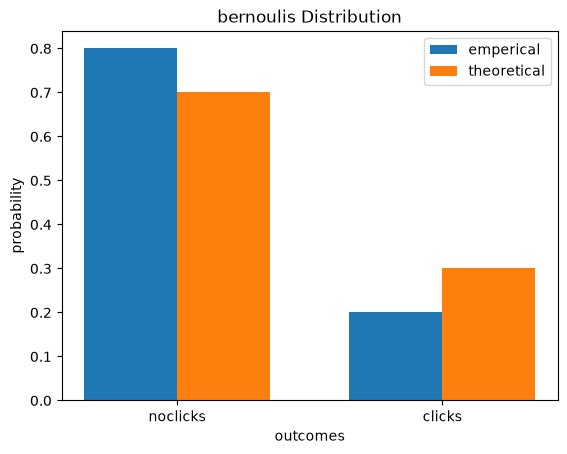

In [20]:
x=[0,1]
emp = [e_pmf[0],e_pmf[1]]
theo = [t_pmf[0],t_pmf[1]]
width = 0.35

plt.bar(np.array(x)-width/2,emp,width,label="emperical")
plt.bar(np.array(x)+width/2,theo,width,label="theoretical")

plt.title("bernoulis Distribution")
plt.xlabel("outcomes")
plt.ylabel("probability")
plt.xticks(x,["noclicks","clicks"])
plt.legend()
plt.show()